# **0. Import thư viện và data**

In [2]:
# Import thư viện
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gdown
from pandas import set_option

In [3]:
# Load data
train_id = '12SQmzC6RUrZWSi9-jK2109Nu3BGDjvU8'
train_name = 'train.csv'
gdown.download(f'https://drive.google.com/uc?id={train_id}', train_name, quiet=False)
df_train_0 = pd.read_csv(train_name)

Downloading...
From: https://drive.google.com/uc?id=12SQmzC6RUrZWSi9-jK2109Nu3BGDjvU8
To: d:\Tai lieu KHDL nam 2\Nhap mon Khoa hoc du lieu\Lab\Homework 2\train.csv
100%|██████████| 2.20M/2.20M [00:00<00:00, 3.34MB/s]


# **1. Data Reprocessing**

In [4]:
df_train = df_train_0.copy()

In [5]:
# Schema
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  str    
 3   Manufacturer      19237 non-null  str    
 4   Model             19237 non-null  str    
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  str    
 7   Leather interior  19237 non-null  str    
 8   Fuel type         19237 non-null  str    
 9   Engine volume     19237 non-null  str    
 10  Mileage           19237 non-null  str    
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  str    
 13  Drive wheels      19237 non-null  str    
 14  Doors             19237 non-null  str    
 15  Wheel             19237 non-null  str    
 16  Color             19237 non-null  str    
 17  Airb

## **1.1. Data Cleaning**

In [6]:
# Số NaN ở mỗi cột
df_train.isnull().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [7]:
# Số dòng trùng
df_train.duplicated().sum()

np.int64(313)

In [8]:
# Xóa các dòng trùng
df_train.drop_duplicates(inplace=True)

In [9]:
# Kiểm tra lại
df_train.duplicated().sum()

np.int64(0)

## **1.2. Data Wrangling**

### a) Đổi kiểu dữ liệu

**Ghi chú**:
- `ID` nên được định dạng là biến **object**.
- `Levy`, `Engine volume`, `Mileage` là những **numerical** features nhưng đang được định dạng là object.
- Kiểm tra `Airbags` và `Cylinders` để quyết định xem nên được định dạng kiểu numerical hay categorical.
- Kiểm tra `Doors` vì sao hiện tại đang là object.
- `Leather interior` nên được định dạng là kiểu **bool** (= True nếu Yes, = False nếu No)
- Các cột object còn lại (`Manufacturer`, `Model`, `Category`, `Fuel type`, `Gear box type`, `Drive wheels`, `Wheel`, `Color`) nên được định dạng là biến **categorical** thay vì object.

In [10]:
# Xử lý cột ID

# Chuyển đổi ID sang object
df_train["ID"] = df_train["ID"].astype("object")

In [11]:
# Xử lý các cột Levy, Engine volume, Mileage
# Levy

# Xem những giá trị không phải numerical của Levy
mask = pd.to_numeric(df_train["Levy"], errors="coerce").isna()
df_train.loc[mask, "Levy"].unique()

<StringArray>
['-']
Length: 1, dtype: str

In [12]:
# Xử lý các cột Levy, Engine volume, Mileage
# Levy

# Chuyển đổi Levy sang numerical
df_train["Levy"] = pd.to_numeric(df_train["Levy"], errors="coerce")

In [13]:
# Xử lý các cột Levy, Engine volume, Mileage
# Engine volume

# Xem những giá trị không phải numerical của Engine volume
mask = pd.to_numeric(df_train["Engine volume"], errors="coerce").isna()
df_train.loc[mask, "Engine volume"].unique()

<StringArray>
['2.0 Turbo', '2.2 Turbo', '3.0 Turbo', '1.4 Turbo', '1.5 Turbo', '1.6 Turbo',
 '2.3 Turbo', '2.8 Turbo', '1.8 Turbo', '2.4 Turbo', '3.5 Turbo', '3.2 Turbo',
 '1.3 Turbo', '2.5 Turbo', '1.9 Turbo', '4.4 Turbo', '4.7 Turbo', '0.2 Turbo',
 '4.8 Turbo', '4.6 Turbo', '1.2 Turbo', '1.7 Turbo', '6.3 Turbo', '2.7 Turbo',
 '2.9 Turbo', '4.0 Turbo', '3.6 Turbo', '3.7 Turbo', '5.5 Turbo', '2.1 Turbo',
 '0.7 Turbo', '0.6 Turbo', '1.0 Turbo', '4.5 Turbo', '0.8 Turbo', '4.2 Turbo',
 '5.0 Turbo', '5.7 Turbo', '0.4 Turbo', '5.4 Turbo', '0.3 Turbo', '1.1 Turbo']
Length: 42, dtype: str

In [14]:
# Xử lý các cột Levy, Engine volume, Mileage
# Engine volume

# Tách cột Turbo
df_train["Turbo"] = df_train["Engine volume"].str.contains("Turbo").astype(bool)
# Chuyển đổi Engine volume sang numerical
df_train["Engine volume"] = df_train["Engine volume"].str.replace("Turbo", "", regex=False)
# Convert sang số
df_train["Engine volume"] = pd.to_numeric(df_train["Engine volume"])

In [15]:
# Xử lý các cột Levy, Engine volume, Mileage
# Mileage

# Xem những giá trị không phải numerical của Mileage
mask = pd.to_numeric(df_train["Mileage"], errors="coerce").isna()
df_train.loc[mask, "Mileage"].unique()

<StringArray>
['186005 km', '192000 km', '200000 km', '168966 km',  '91901 km', '160931 km',
 '258909 km', '216118 km', '398069 km', '128500 km',
 ...
 '135410 km',  '18500 km',  '52456 km',  '65691 km', '158130 km',  '23430 km',
 '132700 km', '140607 km', '307325 km', '186923 km']
Length: 7687, dtype: str

In [16]:
# Xử lý các cột Levy, Engine volume, Mileage
# Mileage

# Loại bỏ đơn vị
df_train["Mileage"] = df_train["Mileage"].str.replace(" km", "", regex=False)
# Chuyển sang số
df_train["Mileage"] = pd.to_numeric(df_train["Mileage"])

In [17]:
# Xử lý các cột `Airbags` và `Cylinders`

# Kiểm tra phân phối dữ liệu
df_train[["Airbags", "Cylinders"]].describe()

,Airbags,Cylinders
count,18924.000000,18924.000000
mean,6.568379,4.580216
std,4.322323,1.200223
min,0.000000,1.000000
25%,4.000000,4.000000
50%,6.000000,4.000000
75%,12.000000,4.000000
max,16.000000,16.000000


In [18]:
# Xử lý `Airbags` và `Cylinders` để quyết định xem nên được định dạng kiểu numerical hay categorical.

# Chuyển sang category
df_train["Airbags"] = df_train["Airbags"].astype("category")
df_train["Cylinders"] = df_train["Cylinders"].astype(int).astype("category")

In [19]:
# Xử lý Doors

# Kiểm tra các giá trị duy nhất
df_train["Doors"].unique()

<StringArray>
['04-May', '02-Mar', '>5']
Length: 3, dtype: str

In [20]:
# Xử lý Doors

# Chuyển sang category, với nhãn phân loại dễ hiểu hơn
door_mapping = {
    '02-Mar': '2-3',
    '04-May': '4-5',
    '>5': '5+'
}

# Áp dụng thay thế
df_train["Doors"] = df_train["Doors"].replace(door_mapping).astype("category")

In [21]:
# Xử lý cột Leather interior

# Chuyển đổi Leather interior sang dạng bool
df_train["Leather interior"] = df_train["Leather interior"].map({"Yes": True, "No": False})

In [22]:
# Xử lý các cột Manufacturer, Model, Category, Fuel type, Gear box type, Drive wheels, Wheel, Color

# Chuyển đổi sang dạng category
df_train["Manufacturer"] = df_train["Manufacturer"].astype("category")
df_train["Model"] = df_train["Model"].astype("category")
df_train["Category"] = df_train["Category"].astype("category")
df_train["Fuel type"] = df_train["Fuel type"].astype("category")
df_train["Gear box type"] = df_train["Gear box type"].astype("category")
df_train["Drive wheels"] = df_train["Drive wheels"].astype("category")
df_train["Wheel"] = df_train["Wheel"].astype("category")
df_train["Color"] = df_train["Color"].astype("category")

**Nhận xét:** Kết quả sau khi chuyển đổi:
- `ID` chuyển sang dạng **object**.
- `Levy`, `Engine volume`, `Mileage` chuyển sang dạng **numerical**.
- `Airbags` và `Cylinders` chuyển sang dạng **categorical**.
- `Doors` chuyển sang dạng **categorical** với nhãn phân loại dễ hiểu hơn.
- `Leather interior` chuyển sang dạng **bool** (= True nếu Yes, = False nếu No)
- Các cột object còn lại (`Manufacturer`, `Model`, `Category`, `Fuel type`, `Gear box type`, `Drive wheels`, `Wheel`, `Doors`, `Color`) chuyển sang dạng **categorical**.

### b) Thêm cột mới

**Ghi chú:**
- Tạo biến mới `Age` = Current year - Prod. year để giúp mô hình hiểu mối quan hệ giữa độ cũ của xe và giá của xe.
- Kiểm tra lại missing value, tạo cờ.

In [23]:
# Thêm biến Age
df_train["Age"] = pd.Timestamp.now().year - df_train["Prod. year"]

In [24]:
# Số NaN ở mỗi cột
df_train.isnull().sum()

ID                     0
Price                  0
Levy                5709
Manufacturer           0
Model                  0
Prod. year             0
Category               0
Leather interior       0
Fuel type              0
Engine volume          0
Mileage                0
Cylinders              0
Gear box type          0
Drive wheels           0
Doors                  0
Wheel                  0
Color                  0
Airbags                0
Turbo                  0
Age                    0
dtype: int64

In [25]:
# Xử lý Levy --> Gán NaN = 0, thêm cờ cảnh báo missing levy
df_train["Levy missing"] = df_train["Levy"].isna().astype(bool)
df_train["Levy"] = df_train["Levy"].fillna(0)

**Nhận xét:** Kết quả sau khi xử lý:
- Điền 0 vào những ô NaN trong cột `Levy`.
- Thêm biến `Levy missing` để đánh dấu giá trị cột `Levy` ban đầu có NaN hay không (= True nếu ban đầu là NaN, = False nếu ngược lại).
- Thêm biến `Age` đo tuổi của xe.

## **1.3. Data Description**

In [26]:
# Kiểm tra lại schema
df_train.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   ID                18924 non-null  object  
 1   Price             18924 non-null  int64   
 2   Levy              18924 non-null  float64 
 3   Manufacturer      18924 non-null  category
 4   Model             18924 non-null  category
 5   Prod. year        18924 non-null  int64   
 6   Category          18924 non-null  category
 7   Leather interior  18924 non-null  bool    
 8   Fuel type         18924 non-null  category
 9   Engine volume     18924 non-null  float64 
 10  Mileage           18924 non-null  int64   
 11  Cylinders         18924 non-null  category
 12  Gear box type     18924 non-null  category
 13  Drive wheels      18924 non-null  category
 14  Doors             18924 non-null  category
 15  Wheel             18924 non-null  category
 16  Color             18924 non-null  cate

Dữ liệu `df_train` có 18924 dòng, 21 cột đã được làm sạch. Trong đó, thông tin các cột như sau:

0. **ID** - object: Mã định danh của mỗi chiếc xe
1. **Price** - int64: Giá bán của xe (target).
2. **Levy** - float64: Thuế/phí nhập khẩu hoặc phí đăng ký xe.
3. **Manufacturer** - category:	Hãng sản xuất xe.
4. **Model** - category:	Dòng xe cụ thể của hãng.
5. **Prod. year** - int64: Năm sản xuất của xe.
6. **Category** - category: Loại xe.
7. **Leather interior** - bool: Nội thất da hay không (= True nếu có, = False nếu không có).
8. **Fuel type** - category: Loại nhiên liệu sử dụng.
9. **Engine volume** - float64:	Dung tích động cơ
10. **Mileage** - int64: Số km đã đi của xe.
11. **Cylinders** - float64: Số xi-lanh của động cơ.
12. **Gear box type** - category: Loại hộp số.
13. **Drive wheels** - category: Hệ dẫn động.
14. **Doors** - category:	Số cửa xe (ở dạng khoảng, không phải số liên tục).
15. **Wheel** - category:	Vị trí vô lăng.
16. **Color** - category: Màu xe
17. **Airbags** - int64: Số lượng túi khí được trang bị trên xe.
18. **Turbo** - bool: Có động cơ turbo hay không (= True nếu có, = False nếu không có).
19. **Age** - int64: Tuổi của xe
20. **Levy missing** - bool: Levy ban đầu có missing hay không (= True nếu missing ban đầu, = False nếu không)

# **2. Prepare Data**

In [27]:
df_model = df_train.copy()

In [28]:
# Loại bỏ biến ID, Prod. year (vì đã có biến giá trị hơn là Age)
df_model.drop(["ID", "Prod. year"], axis=1, inplace=True)

In [29]:
# Schema
df_model.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Price             18924 non-null  int64   
 1   Levy              18924 non-null  float64 
 2   Manufacturer      18924 non-null  category
 3   Model             18924 non-null  category
 4   Category          18924 non-null  category
 5   Leather interior  18924 non-null  bool    
 6   Fuel type         18924 non-null  category
 7   Engine volume     18924 non-null  float64 
 8   Mileage           18924 non-null  int64   
 9   Cylinders         18924 non-null  category
 10  Gear box type     18924 non-null  category
 11  Drive wheels      18924 non-null  category
 12  Doors             18924 non-null  category
 13  Wheel             18924 non-null  category
 14  Color             18924 non-null  category
 15  Airbags           18924 non-null  category
 16  Turbo             18924 non-null  bool

# **3. EDA**

## **3.1. Numerical Features**

### a) Raw EDA

In [30]:
# Lọc ra numerical data & features
numerical_data = df_model.select_dtypes(include='number')
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 5 numerical features: 

['Price', 'Levy', 'Engine volume', 'Mileage', 'Age']


In [31]:
# Thống kê của các numerical features
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,18924.0,1.858744e+04,1.921356e+05,1.0,5331.00,13172.0,22063.00,2.630750e+07
Levy,18924.0,6.328865e+02,5.682737e+02,0.0,0.00,642.0,917.00,1.171400e+04
Engine volume,18924.0,2.306251e+00,8.775910e-01,0.0,1.80,2.0,2.50,2.000000e+01
Mileage,18924.0,1.555373e+06,4.880221e+07,0.0,70195.75,126400.0,189119.75,2.147484e+09
Age,18924.0,1.508576e+01,5.665749e+00,6.0,11.00,14.0,17.00,8.700000e+01


In [32]:
# Phương sai (var)
numerical_data.var()

Price            3.691610e+10
Levy             3.229350e+05
Engine volume    7.701660e-01
Mileage          2.381655e+15
Age              3.210071e+01
dtype: float64

In [33]:
# Độ lệch
numerical_data.skew()


Price            135.387726
Levy               2.403811
Engine volume      2.208051
Mileage           38.578517
Age                2.088595
dtype: float64

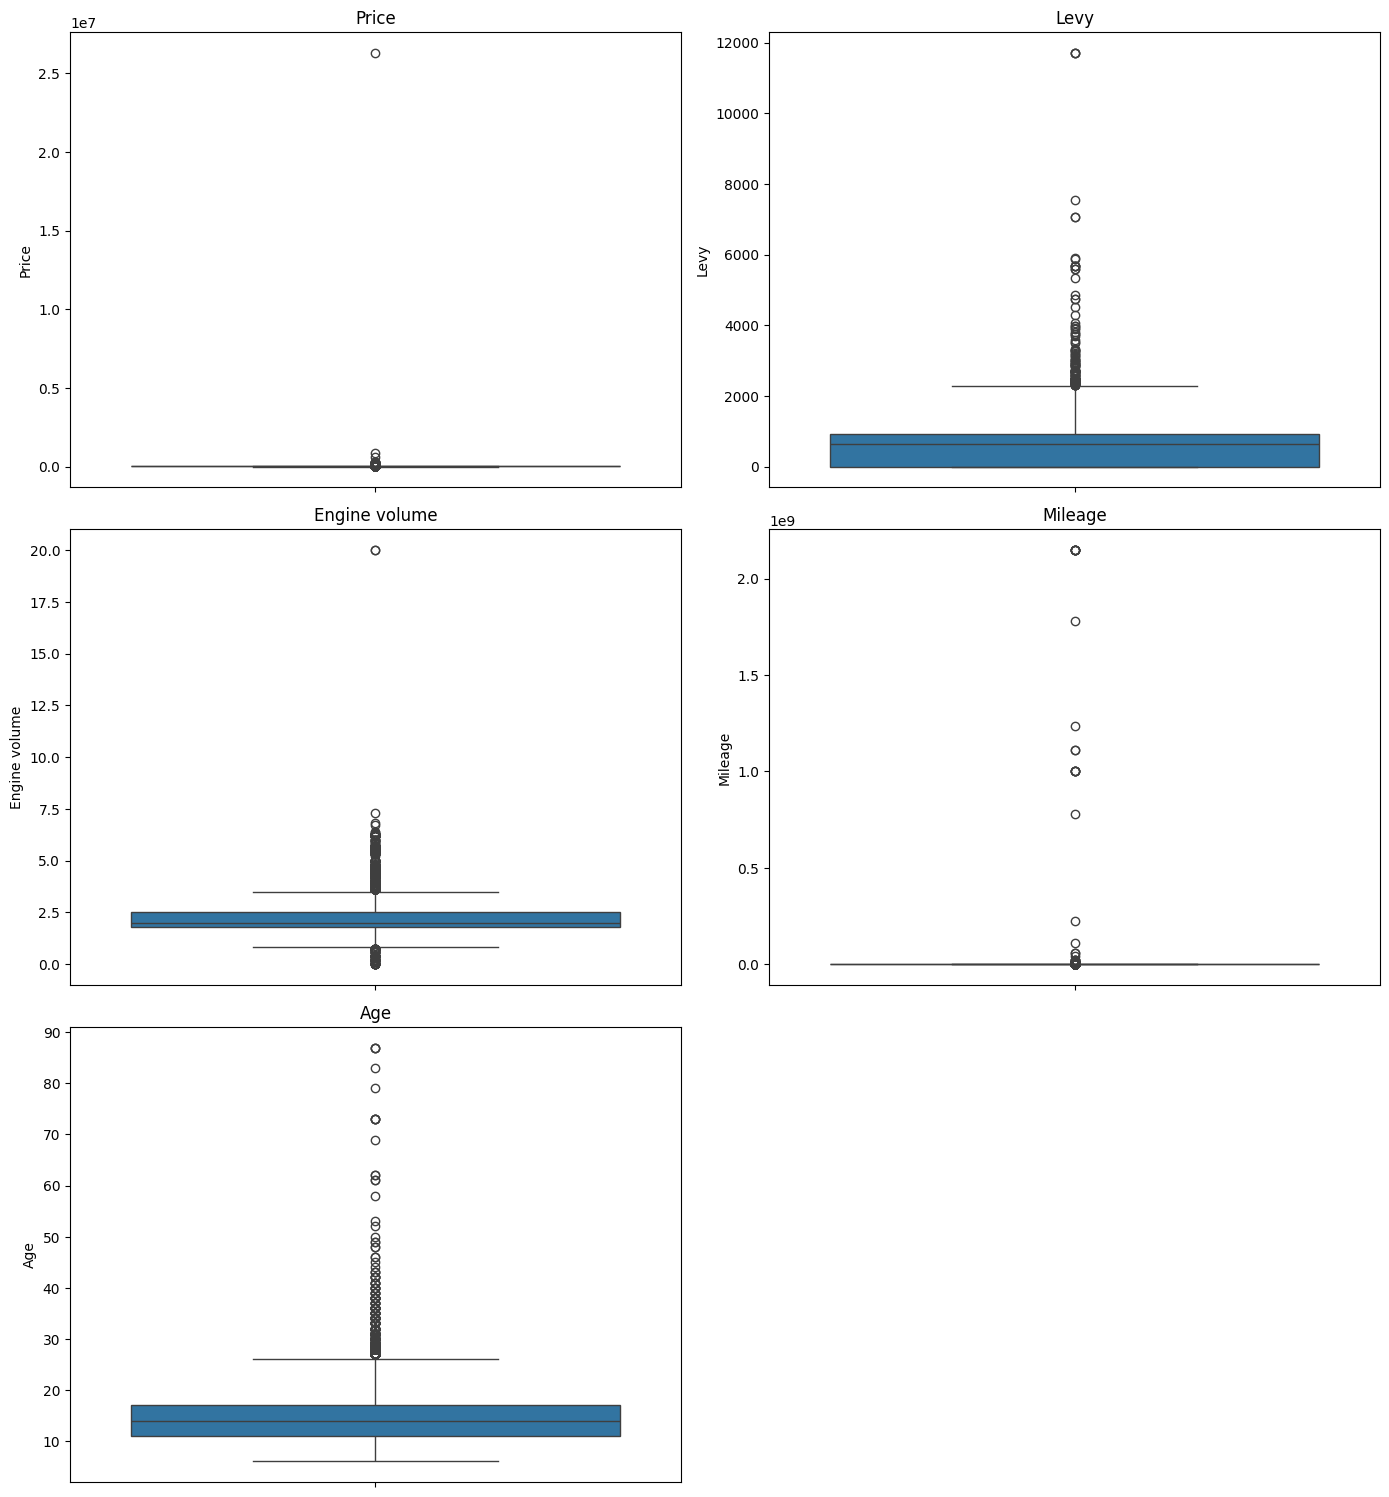

In [34]:
# Vẽ boxlot cho các numerical features
plt.figure(figsize=(14, 20))

for i, col in enumerate(numerical_features):
    plt.subplot(4, 2, i + 1)
    sns.boxplot(y=numerical_data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

**Insight:** Hầu như tất cả các biến đều xuất hiện rất nhiều giá trị ngoại lai, cho thấy dữ liệu có độ lệch lớn hoặc chứa nhiều giá trị cực đoan.
- Price (Giá): Có giá trị ngoại lai cực kỳ cao so với phần còn lại, đó là những xe có giá trị vượt trội hoàn toàn so với phân khúc phổ thông. Ngoài ra, theo thống kê cho thấy có xe giá chỉ 1 USD (vô lý).
- Levy (Thuế): Có lượng ngoại lai dày đặc ở phía trên cho thấy một nhóm lớn các xe có mức thuế cao bất thường, có thể là do cấu tạo động cơ hoặc quy định thuế đặc thù đối với các dòng xe đó.
- Engine volume (Dung tích động cơ): Có các giá trị ngoại lai đáng chú ý, đặc biệt là một giá trị rất cao (lên đến 20). Ngoài ra theo thống kê, có những xe có dung tích là 0 (vô lý).
- Mileage (Số km đã đi): Có những ngoại lai rất vô lý (hơn 2 tỷ km), nên được loại bỏ trước khi đưa vào mô hình.
- Age (Tuổi của xe): Có một dải ngoại lai kéo dài t 30-90 năm tuổi, đây là những chiếc xe cổ nhưng có thể "nhiễu" đối với mô hình dự đoán.

**Ghi chú:** Trước khi xây dựng mô hình, nên xem xét xử lý các giá trị ngoại lai này.
- **Kiểm tra** xe có giá cao bất thường.
- Ngoại lai do lỗi dữ liệu (**Cần loại bỏ**): Điển hình là Mileage > 1 triệu km và Engine volume > 10.
- Ngoại lai do đặc thù phân khúc (**Cần cân nhắc**): Như Price cực cao hoặc Age rất lớn. Thay vì xóa, có thể cân nhắc việc thu hẹp phạm vi dữ liệu (ví dụ: chỉ train cho xe dưới 40 năm tuổi) để mô hình tập trung vào phân khúc xe phổ biến nhất.


### b) Data Handling - Outliers

In [35]:
# Kiểm tra xe có giá cao bất thường (upper quantile = 0.995)
df_model[df_model["Price"] > df_model["Price"].quantile(0.995)]

,Price,Levy,Manufacturer,Model,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags,Turbo,Age,Levy missing
573,119172,1301.0,BMW,M6,Coupe,True,Petrol,4.4,33500,8,Tiptronic,Rear,4-5,Left wheel,White,12,True,12,False
740,117290,0.0,MERCEDES-BENZ,S 350 W2222,Sedan,True,Diesel,3.0,222222,6,Tiptronic,Rear,4-5,Left wheel,Black,12,True,12,True
1027,131716,0.0,TOYOTA,Land Cruiser Prado,Jeep,True,Diesel,3.0,59826,4,Automatic,4x4,4-5,Left wheel,Black,12,True,8,True
1145,194438,0.0,MERCEDES-BENZ,G 350,Jeep,True,Diesel,3.0,94000,6,Automatic,4x4,4-5,Left wheel,Black,6,True,13,True
1179,133284,690.0,LEXUS,RX 450,Jeep,True,Hybrid,3.5,55000,6,Tiptronic,4x4,4-5,Left wheel,Black,12,False,10,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18018,127000,0.0,JEEP,Cherokee,Jeep,True,Diesel,3.0,26713,6,Automatic,4x4,4-5,Left wheel,Grey,12,True,8,True
18231,131716,0.0,TOYOTA,Land Cruiser,Jeep,True,Diesel,3.0,59826,4,Automatic,4x4,4-5,Left wheel,Black,12,True,8,True
18640,111332,0.0,LEXUS,GX 460,Jeep,True,Petrol,4.6,92800,8,Tiptronic,4x4,4-5,Left wheel,Black,10,False,12,True
18815,111002,1228.0,FORD,Explorer,Jeep,True,Petrol,2.3,30475,4,Automatic,Front,4-5,Left wheel,Grey,4,False,8,False


In [36]:
# Loại bỏ outliers do lỗi dữ liệu (Mileage > 1000 000 km, Engine volume > 10L)
df_model = df_model[(df_model["Mileage"] <= 1000000) & (df_model["Engine volume"] <= 10)]

# Loại bỏ outliers về Price (lower quantile = 0.001, upper quantile = 0.995)
df_model = df_model[df_model["Price"] <= df_model["Price"].quantile(0.995)]

# Cập nhật numerical data sau khi loại bỏ outliers
numerical_data = df_model.select_dtypes(include='number')
numerical_features=numerical_data.columns.tolist()

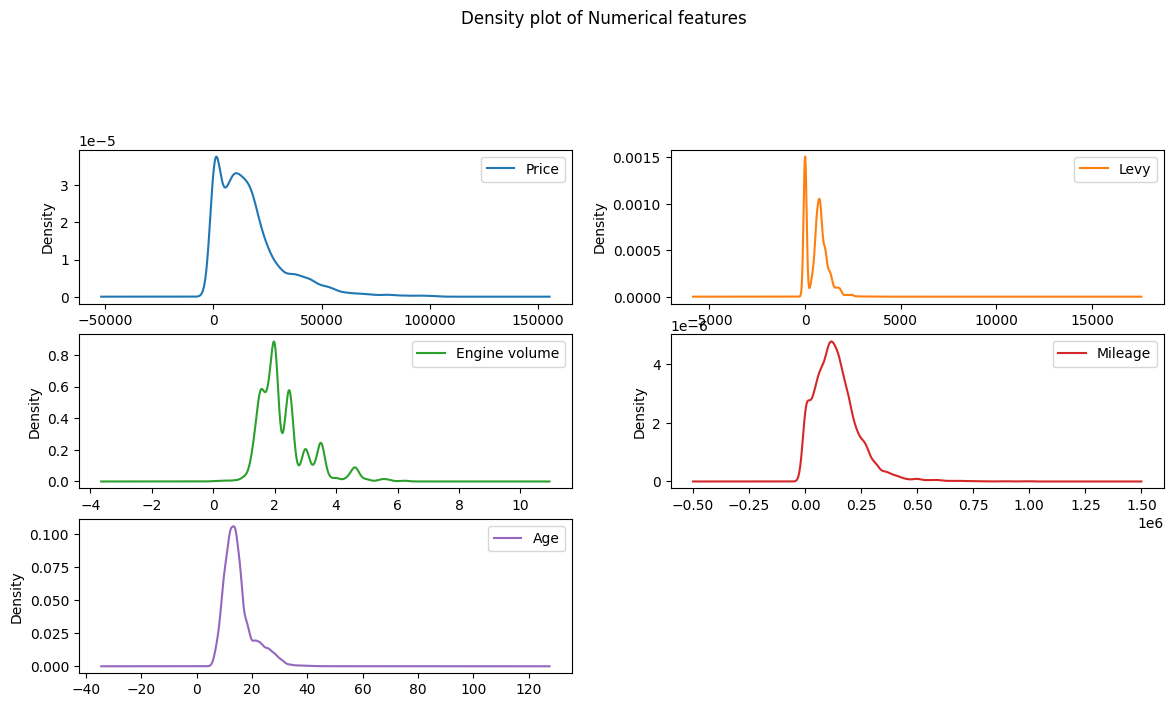

In [ ]:
# Phân phối của các numerical features
numerical_data.plot(
    kind='density',
    figsize=(14,14),
    subplots=True,
    layout=(6,2),
    title="Density plot of Numerical features",
    sharex=False)
plt.show()

**Insight:**
- Price (Giá): Biểu đồ cho thấy một đỉnh nhọn cực cao tại giá trị gần bằng 0. Điều này chỉ ra rằng phần lớn dữ liệu về giá tập trung ở mức rất thấp.
- Levy (Thuế): Phân bố lệch phải rõ rệt với một đỉnh chính gần 0 và một phần đuôi kéo dài sang phải. Có một nhóm nhỏ giá trị dương tập trung, cho thấy phần lớn xe có mức thuế thấp, nhưng có những xe có mức thuế rất cao.
- Engine volume (Dung tích động cơ): Phân bố có nhiều đỉnh nhỏ (multimodal), tập trung chủ yếu trong khoảng từ 1 đến 5.
- Mileage (Số km đã đi): Lệch phải mạnh, đa số xe tập trung ở mức số km thấp (từ 0 đến 250,000 km), nhưng lại có một "cái đuôi" dài kéo đến 1,000,000+ km.
- Age (Tuổi của xe): Phân bố lệch phải cho thấy phần lớn xe trong tập dữ liệu nằm trong độ tuổi từ khoảng 10 đến 20 năm, với đỉnh cao nhất tập trung ở mức khoảng 12-16 năm tuổi. Phân bố này phản ánh rõ ràng đặc tính của tập dữ liệu là tập trung vào các dòng xe đã qua sử dụng một thời gian đáng kể.

**Ghi chú:**
- Biểu đồ phân phối của Price, Levy, Mileage lệch phải mạnh, việc sử dụng **log transformation** đối với model Linear/KNN là cần thiết để dữ liệu gần với phân phối chuẩn hơn.
- **Dùng correlation heatmap** hoặc **scatter plot** để kiểm tra mối quan hệ giữa các biến Levy, Engine volumn, Mileage với Price.

### c) Deep EDA - Correlation Analysis



<Figure size 1400x1400 with 0 Axes>

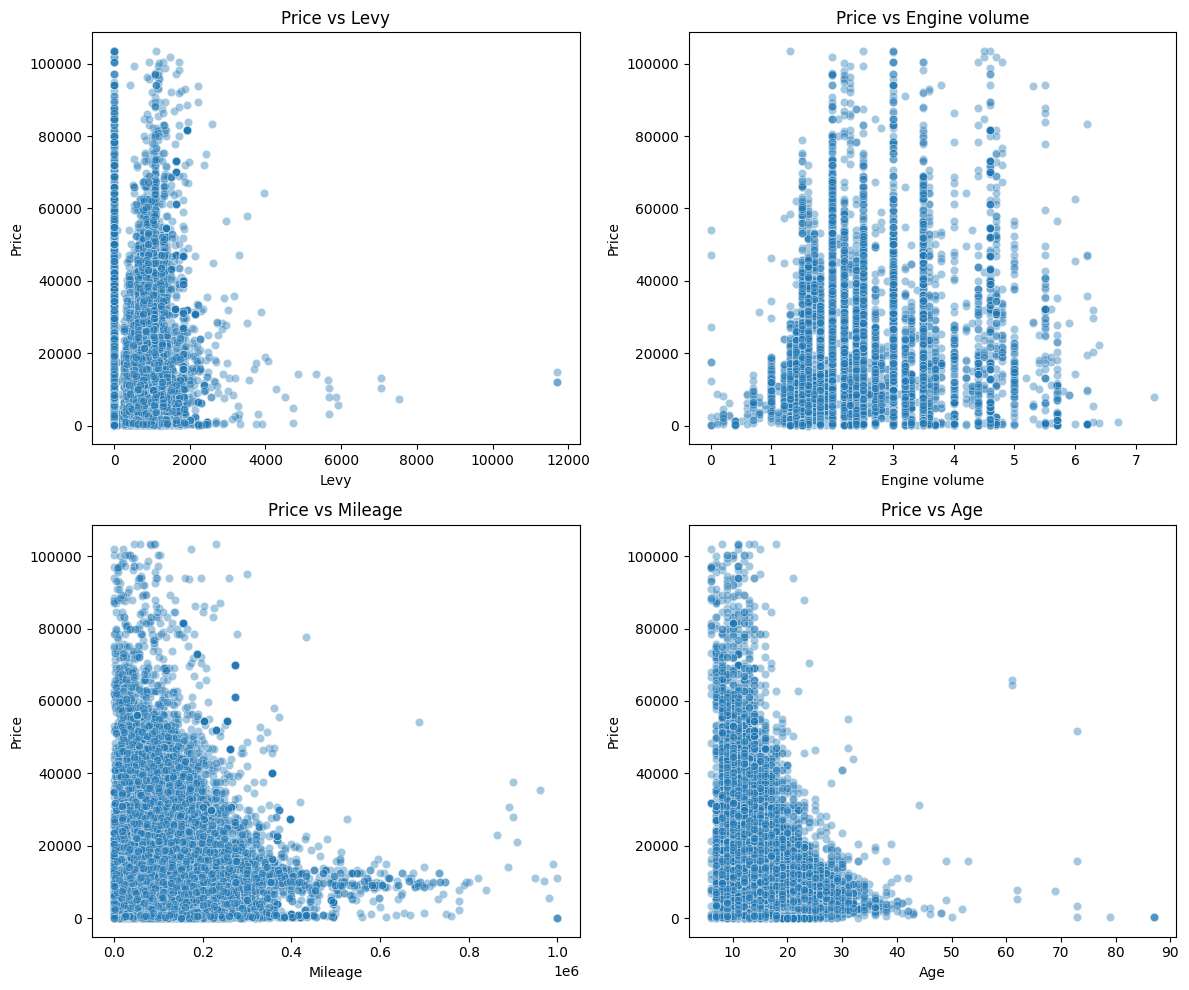

In [38]:
# Scatter plot kiểm tra mối quan hệ tuyến tính giữa các biến Levy, Engine volumn, Mileage, Age với Price
plt.figure(figsize=(14, 14))

num_features = ["Levy", "Engine volume", "Mileage", "Age"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.scatterplot(
        data=df_model,
        x=col,
        y="Price",
        alpha=0.4,
        ax=axes[i]
    )

    axes[i].set_title(f"Price vs {col}")

plt.tight_layout()
plt.show()

**Insight:**
- Cả 4 biểu đồ đều cho thấy sự tồn tại của một số điểm dữ liệu có giá cực cao so với mặt bằng chung (đặc biệt là điểm ở vùng giá trên 800,000). Những giá trị này có thể gây nhiễu và làm sai lệch đường hồi quy của mô hình.
- Mối quan hệ phi tuyến tính:
  - Mileage (Số km đã đi) và Age (Tuổi đời): Có mối quan hệ nghịch biến rõ rệt với Price. Giá xe giảm mạnh khi tuổi đời và số km tăng lên, nhưng xu hướng này có vẻ không phải là đường thẳng hoàn hảo (có dạng cong).
  - Levy: Có sự tập trung dữ liệu lớn ở vùng Levy thấp, phân tán mạnh ở vùng trung bình và thưa dần khi Levy cao.
- Engine volume (Dung tích động cơ): Mối quan hệ không quá rõ ràng. Có vẻ như các xe có dung tích động cơ ở mức trung bình (khoảng 2.0 - 4.0) có dải giá phân bổ rộng hơn, trong khi các giá trị cực thấp hoặc cực cao có mật độ dữ liệu ít hơn.

**Ghi chú:** Có thể thêm feature `Mileage per year` = Mileage / (Age + 1) — cường độ sử dụng. Vì Mileage và Age đều nghịch biến phi tuyến ("dạng cong") với giá, và chúng tương tác với nhau. Một xe 15 năm chạy 50.000 km khác hẳn xe 15 năm chạy 300.000 km — thông tin này không nằm trong Mileage hay Age riêng lẻ. Đây là tín hiệu mới và giúp mọi mô hình.

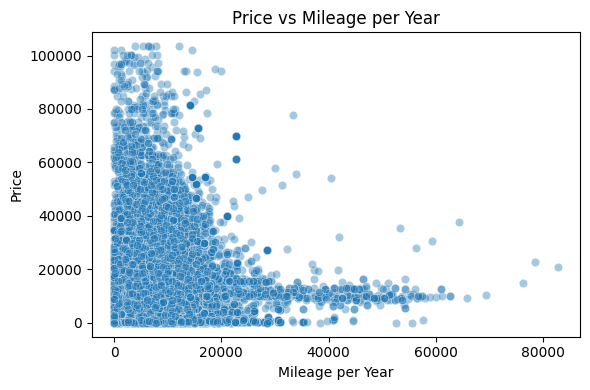

In [39]:
# Thêm feature Mileage per Year
df_model["Mileage per Year"] = df_model["Mileage"] / (df_model["Age"] + 1)  # +1 để tránh chia cho 0 khi Age = 0

# Scatter plot kiểm tra mối quan hệ tuyến tính giữa biến mới Mileage per Year với Price
plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=df_model,
    x="Mileage per Year",
    y="Price",
    alpha=0.4
)   
plt.title("Price vs Mileage per Year")
plt.tight_layout()
plt.show()

**Insight:** Giá xe khấu hao theo đường cong (phi tuyến); giảm cực mạnh khi xe mới đi ít, nhưng "bão hòa" (rẻ bèo) khi xe đi quá nhiều.

**Ghi chú:** Nên dùng log transformation trước khi đưa vào mô hình Linear/KNN hoặc dùng mô hình cây (trees) để nắm bắt đường cong này.

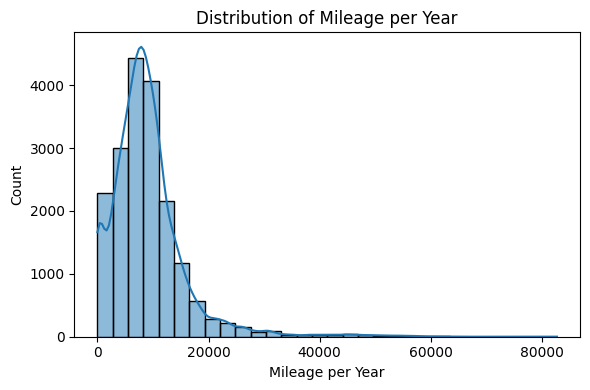

In [40]:
# Phân phối của Mileage per Year
plt.figure(figsize=(6, 4))
sns.histplot(df_model["Mileage per Year"], bins=30, kde=True)
plt.title("Distribution of Mileage per Year")
plt.tight_layout()
plt.show()

**Insight:** Dữ liệu tập trung cực cao ở nhóm "di chuyển ít" (dưới 20.000 dặm/năm). Những chiếc xe có mileage cao (>40.000) chỉ là các ngoại lệ (outliers) hiếm hoi.

In [41]:
# Cập nhật numerical features sau khi thêm biến mới
numerical_data = df_model.select_dtypes(include='number')
numerical_features = numerical_data.columns.tolist()

In [42]:
# Correlation matrix
set_option('display.float_format', '{:,.3f}'.format)
correlation_pearson = numerical_data.corr(method='pearson')
correlation_spearman = numerical_data.corr(method='spearman')
correlation_kendall = numerical_data.corr(method='kendall')

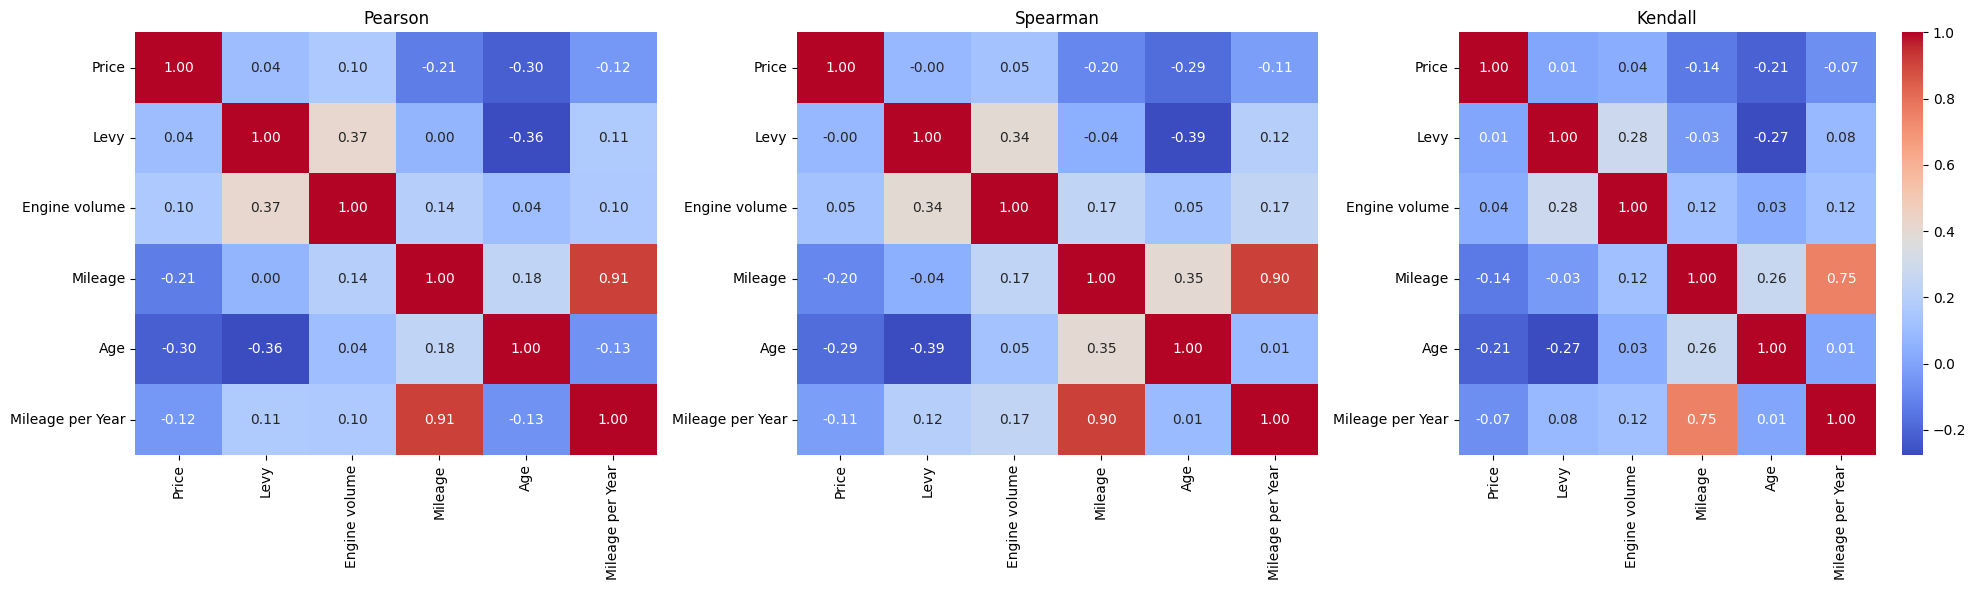

In [67]:
# Vẽ heatmap cho cả 3 loại correlation
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.heatmap(correlation_pearson, ax=axes[0],
            annot=True, fmt=".2f", cmap="coolwarm", cbar=False)
axes[0].set_title("Pearson")

sns.heatmap(correlation_spearman, ax=axes[1],
            annot=True, fmt=".2f", cmap="coolwarm", cbar=False)
axes[1].set_title("Spearman")

sns.heatmap(correlation_kendall, ax=axes[2],
            annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
axes[2].set_title("Kendall")

plt.tight_layout()
plt.show()

In [43]:
# Correlation matrix
# Pearson
correlation_pearson

,Price,Levy,Engine volume,Mileage,Age,Mileage per Year
Price,1.000,0.041,0.102,-0.206,-0.303,-0.118
Levy,0.041,1.000,0.372,0.001,-0.364,0.115
Engine volume,0.102,0.372,1.000,0.138,0.044,0.104
Mileage,-0.206,0.001,0.138,1.000,0.184,0.907
Age,-0.303,-0.364,0.044,0.184,1.000,-0.130
Mileage per Year,-0.118,0.115,0.104,0.907,-0.130,1.000


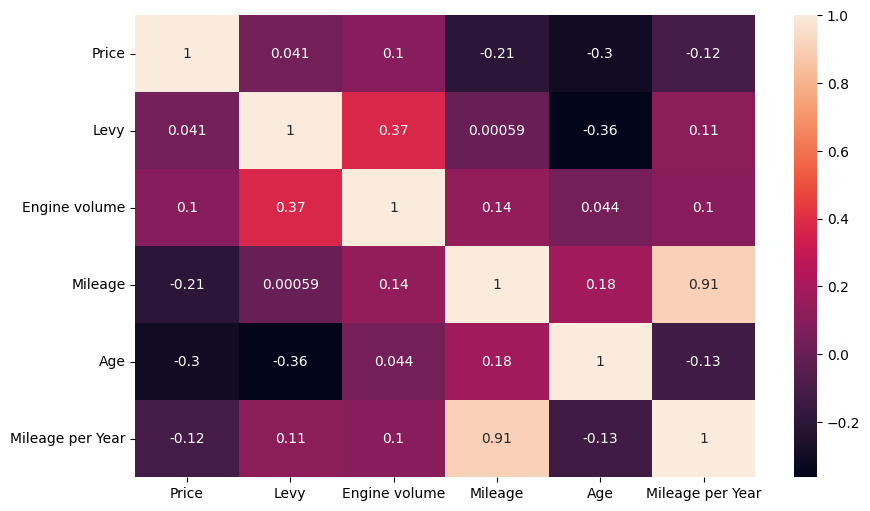

In [44]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(correlation_pearson, ax=ax, annot=True)
plt.show()

In [45]:
# Correlation matrix
# Spearman
correlation_spearman

,Price,Levy,Engine volume,Mileage,Age,Mileage per Year
Price,1.000,-0.001,0.046,-0.197,-0.287,-0.109
Levy,-0.001,1.000,0.342,-0.040,-0.390,0.123
Engine volume,0.046,0.342,1.000,0.169,0.049,0.170
Mileage,-0.197,-0.040,0.169,1.000,0.345,0.903
Age,-0.287,-0.390,0.049,0.345,1.000,0.011
Mileage per Year,-0.109,0.123,0.170,0.903,0.011,1.000


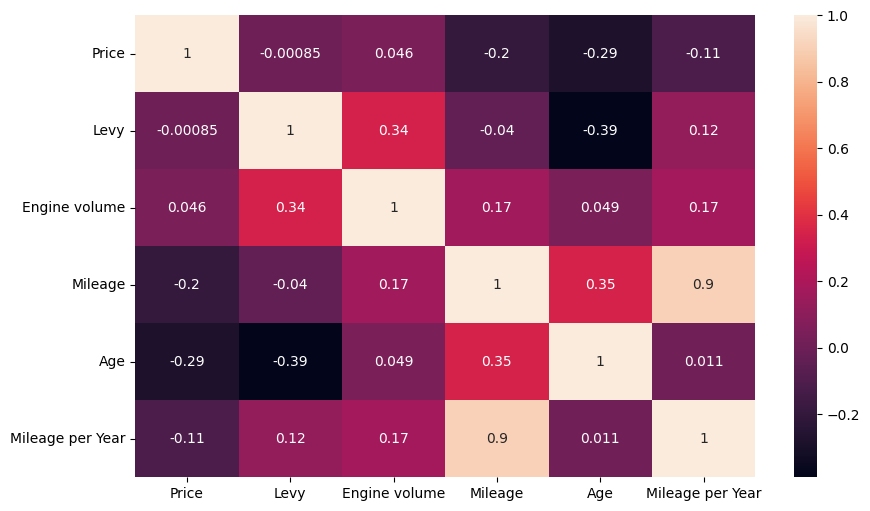

In [46]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(correlation_spearman, ax=ax, annot=True)
plt.show()

In [47]:
# Correlation matrix
# Kendall
correlation_kendall

,Price,Levy,Engine volume,Mileage,Age,Mileage per Year
Price,1.000,0.006,0.037,-0.137,-0.214,-0.073
Levy,0.006,1.000,0.281,-0.032,-0.275,0.085
Engine volume,0.037,0.281,1.000,0.117,0.035,0.118
Mileage,-0.137,-0.032,0.117,1.000,0.264,0.752
Age,-0.214,-0.275,0.035,0.264,1.000,0.006
Mileage per Year,-0.073,0.085,0.118,0.752,0.006,1.000


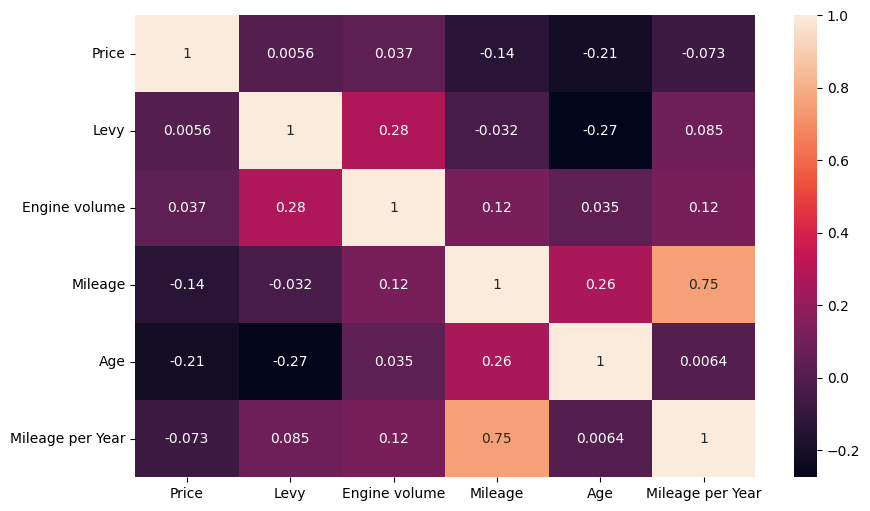

In [48]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(correlation_kendall, ax=ax, annot=True)
plt.show()

**Insight:** Các hệ số tương quan tuyến tính nhìn chung khá thấp (đều nằm trong khoảng [-0.39, 0.37]). Do đó, việc chỉ dựa vào các mô hình hồi quy tuyến tính đơn giản có thể không mang lại kết quả dự báo tốt.

## **3.2. Categorical Features**

### a) Raw EDA

In [49]:
# Lọc ra categorical data & features
categorical_data=df_model.select_dtypes(include= 'category')
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 11 categorical features: 

['Manufacturer', 'Model', 'Category', 'Fuel type', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags']


In [50]:
# Số giá trị duy nhất của các categorical feature
unique_counts=categorical_data.nunique()

for index,i in enumerate(range(len(categorical_features)),start=1):
    print(index, "{a} has {b} unique values".format(a=categorical_features[i], b=unique_counts.iloc[i]))

1 Manufacturer has 63 unique values
2 Model has 1561 unique values
3 Category has 11 unique values
4 Fuel type has 7 unique values
5 Cylinders has 13 unique values
6 Gear box type has 4 unique values
7 Drive wheels has 3 unique values
8 Doors has 3 unique values
9 Wheel has 2 unique values
10 Color has 16 unique values
11 Airbags has 17 unique values


In [51]:
# Lọc ra categorical features có không quá 20 phân loại
categorical_features_less = [col for col in categorical_data.columns if categorical_data[col].nunique() <= 20]
print("Identify categorical columns with 20 or fewer unique values:", categorical_features_less)

Identify categorical columns with 20 or fewer unique values: ['Category', 'Fuel type', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags']


In [52]:
for col in categorical_features_less:
    print(f"🔹 Column: {col}")
    print(categorical_data[col].value_counts(dropna=False))
    print("-" * 50)

🔹 Column: Category
Category
Sedan          8539
Jeep           5317
Hatchback      2786
Minivan         629
Coupe           517
Universal       356
Microbus        293
Goods wagon     224
Pickup           49
Cabriolet        35
Limousine        11
Name: count, dtype: int64
--------------------------------------------------
🔹 Column: Fuel type
Fuel type
Petrol            9838
Diesel            3966
Hybrid            3528
LPG                883
CNG                455
Plug-in Hybrid      85
Hydrogen             1
Name: count, dtype: int64
--------------------------------------------------
🔹 Column: Cylinders
Cylinders
4     14079
6      3324
8       947
5       167
3       106
2        42
1        35
12       34
10       12
16        5
7         3
9         1
14        1
Name: count, dtype: int64
--------------------------------------------------
🔹 Column: Gear box type
Gear box type
Automatic    13220
Tiptronic     3003
Manual        1804
Variator       729
Name: count, dtype: int64
----

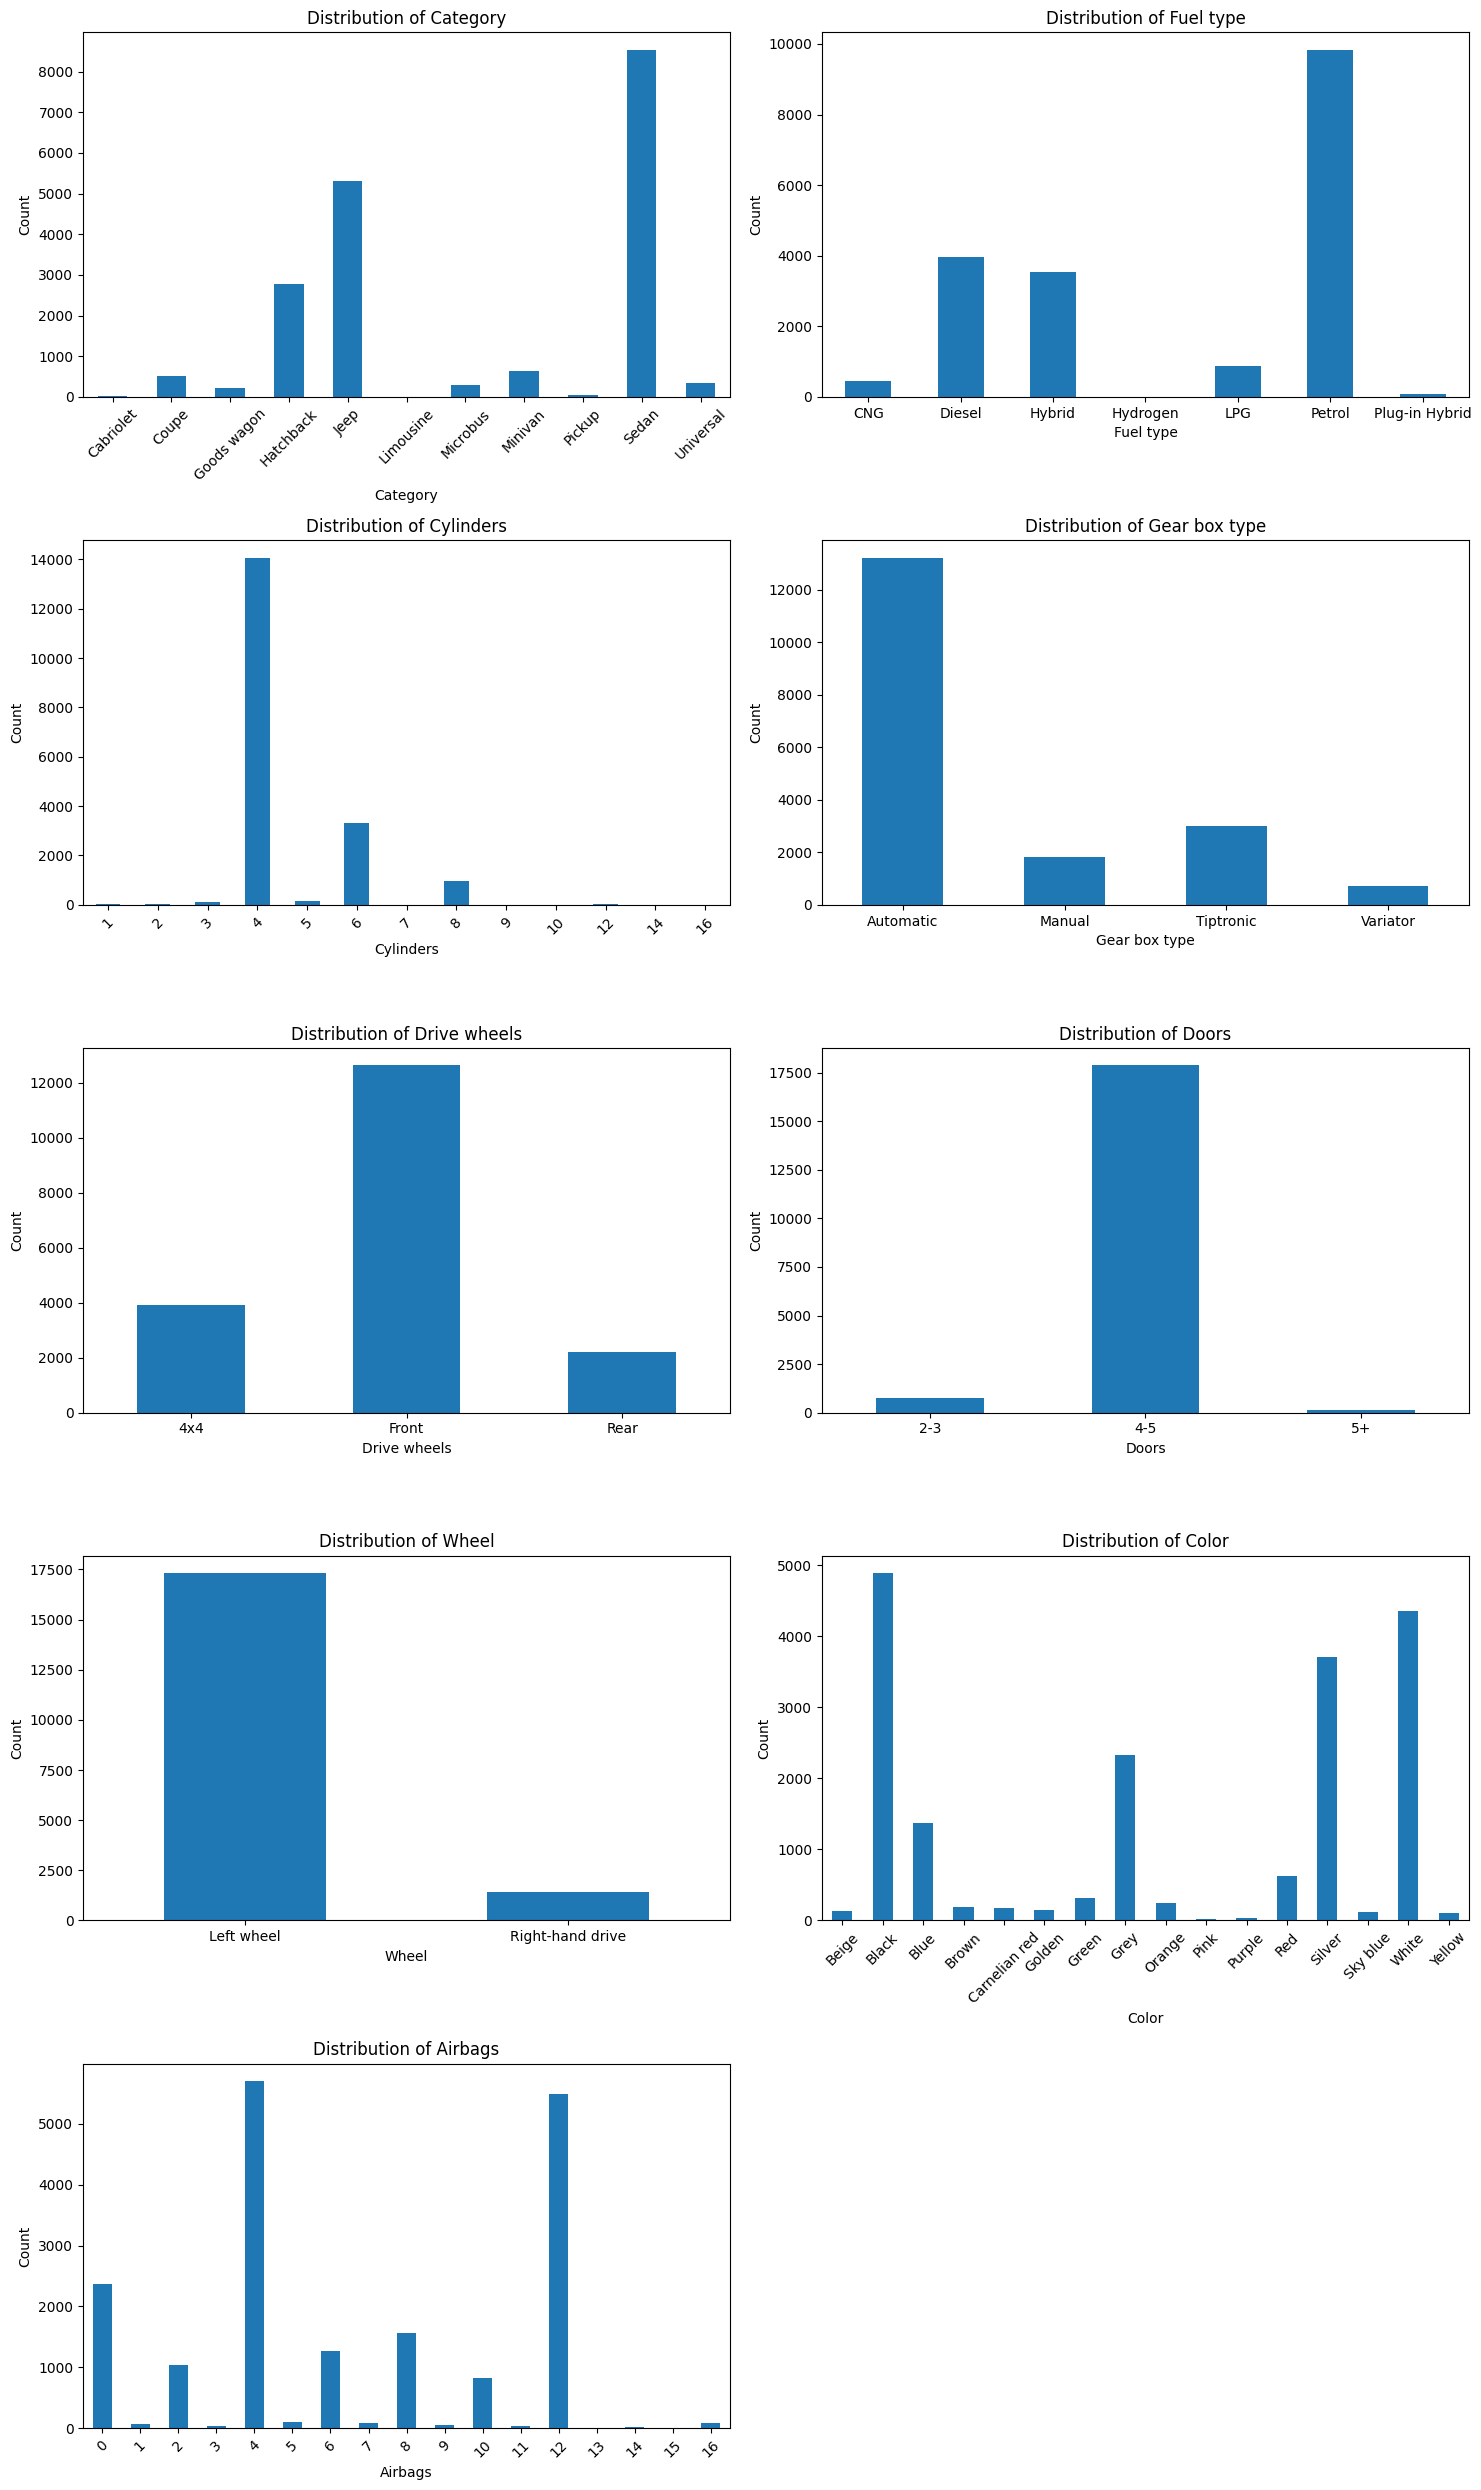

In [ ]:
ncols = 2
nrows = (len(categorical_features_less) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5*nrows))
axes = axes.flatten()

for i, col in enumerate(categorical_features_less):

    n_categories = categorical_data[col].nunique()
    rot = 45 if n_categories > 8 else 0

    categorical_data[col].value_counts().sort_index().plot(
        kind='bar',
        ax=axes[i],
        rot=rot,
        xlabel=col,
        ylabel='Count'
    )
# Thêm title
    axes[i].set_title(f"Distribution of {col}")
# xóa ô thừa
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Insight:**
- Category (Loại xe): Dữ liệu bị lệch rất nặng về dòng Sedan, trong khi các dòng như Limousine, Pickup hay Cabriolet gần như không đáng kể.
- Fuel type (Loại nhiên liệu): Đa số xe chạy Petrol (xăng), tiếp đến là Diesel và Hybrid. Xe chạy Hydrogen gần như không có dữ liệu.
- Cylinders (Số xi lanh): Xe có 4, 6 hoặc 8 xi lanh thống trị hoàn toàn, số còn lại phân bổ rải rác.
- Gear box type (Loại hộp số): Hộp số Automatic (tự động) chiếm đại đa số. Sự chênh lệch này cho thấy thị trường xe này ưu tiên sự tiện lợi.
- Drive wheels (Hệ dẫn động): Dẫn động Front (cầu trước) chiếm ưu thế, tiếp đến là 4x4 và Rear (cầu sau). Biến này ảnh hưởng trực tiếp đến khả năng vận hành và phân khúc giá (ví dụ: xe 4x4 thường đắt hơn do tính năng off-road)
- Doors (Số cửa): Hầu hết xe là dòng 4-5 cửa. Số cửa có thể không mang lại nhiều giá trị phân biệt vì hầu hết dữ liệu đều rơi vào một nhóm.
- Wheel (Vị trí vô lăng): Left wheel (Vô lăng trái) chiếm đa số tuyệt đối. Đây là biến mang tính chất địa lý, xe "Right-hand drive" ở các quốc gia lái xe bên phải thường là xe nhập khẩu đặc biệt, giá có thể rất cao hoặc rất thấp tùy mục đích (đồ cổ/siêu xe).
- Color (Màu sắc): Các màu trung tính như Black, White, Silver chiếm tỷ trọng lớn nhất. Biến này thường không ảnh hưởng quá lớn đến giá trừ một số màu đặc biệt (như màu độc lạ của siêu xe).
- Airbags (Số túi khí): Phân bổ tập trung cao ở mức 4 và 12 túi khí.

**Ghi chú**
- Để giúp mô hình không bị "nhiễu" bởi các nhóm dữ liệu hiếm, nên **gom nhóm các danh mục có tần suất thấp** (Category là Limousine, Pickup hay Cabriolet, Fuel type là Hydrogen)
- **Kiểm tra những xe có số Cylinders quá lẻ hoặc quá cao**, giá có thể khác biệt so với bình thường.
- **Kiểm tra mối quan hệ** giữa các biến Gear box type, Drive wheels, Wheel với Price.
- Nên **dùng Target Encoding** để biến màu sắc thành giá trị trung bình về giá.

In [60]:
# Xem những categorical features trên 20 phân loại
categorical_features_more = [col for col in categorical_data if categorical_data[col].nunique() > 20]
print("Identify categorical columns with more 20 unique values:", categorical_features_more)

Identify categorical columns with more 20 unique values: ['Manufacturer', 'Model']


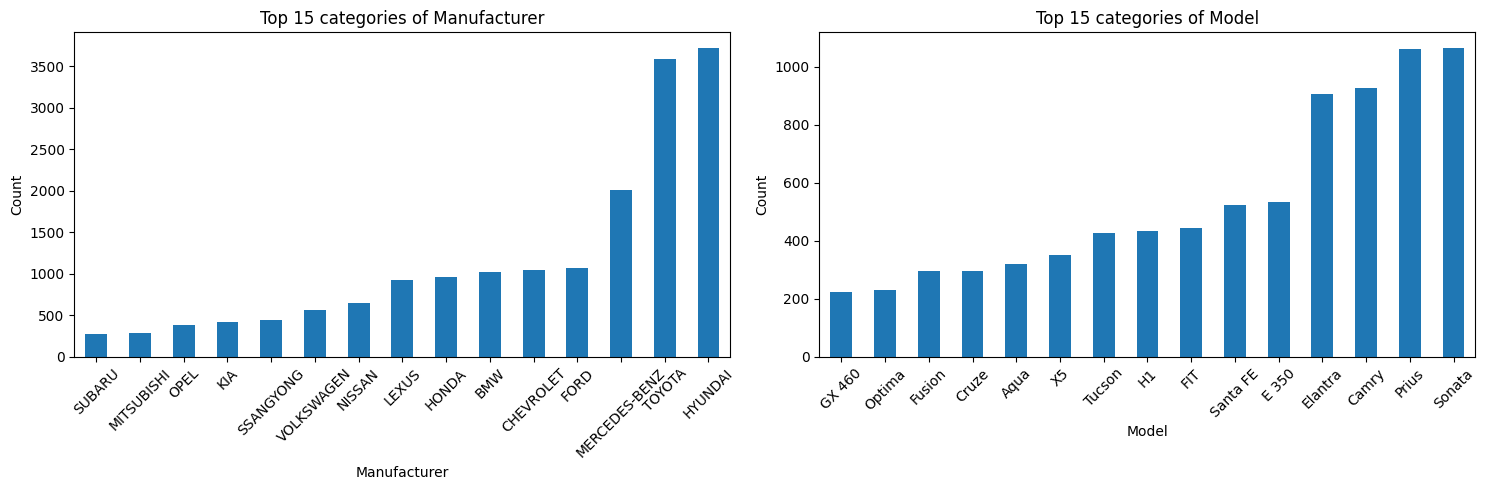

In [65]:
ncols = 2
nrows = (len(categorical_features_more) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5*nrows))
axes = axes.flatten()

for i, col in enumerate(categorical_features_more):

    n_categories = categorical_data[col].nunique()
    rot = 45 if n_categories > 8 else 0

    categorical_data[col].value_counts().head(15).sort_values().plot(
        kind='bar',
        ax=axes[i],
        rot=rot,
        xlabel=col,
        ylabel='Count'
    )
# Thêm title
    axes[i].set_title(f"Top 15 categories of {col}")
# xóa subplot thừa
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Insight:**
- Manufacturer (Hãng sản xuất): Có sự phân hóa cực kỳ rõ rệt: Huyndai và Toyota chiếm ưu thế tuyệt dối. Đây là biến quan trọng mang thông tin về thương hiệu, ảnh hưởng trực tiếp đến giá trị bán lại.
- Model (Dòng xe): Các dòng xe phổ thông như Prius, Sonata, Camry, Elantra xuất hiện với tần suất rất cao, cho thấy tập dữ liệ tập trung vào dòng xe phổ thông, không phải xe sưu tầm hay siêu xe.

**Ghi chú:**
- Với Manufacturer, nên **dùng Target Encoding** (thay hãng bằng giá trung bình của hãng đó) hoặc **Label Encoding** nếu dùng XGBoost/ CatBoost.
- Với Model, nên **dùng Target Encoding** kết hợp với **Smoothing** để tránh bị overfit với các dòng xe ít mẫu.

### b) Deep EDA

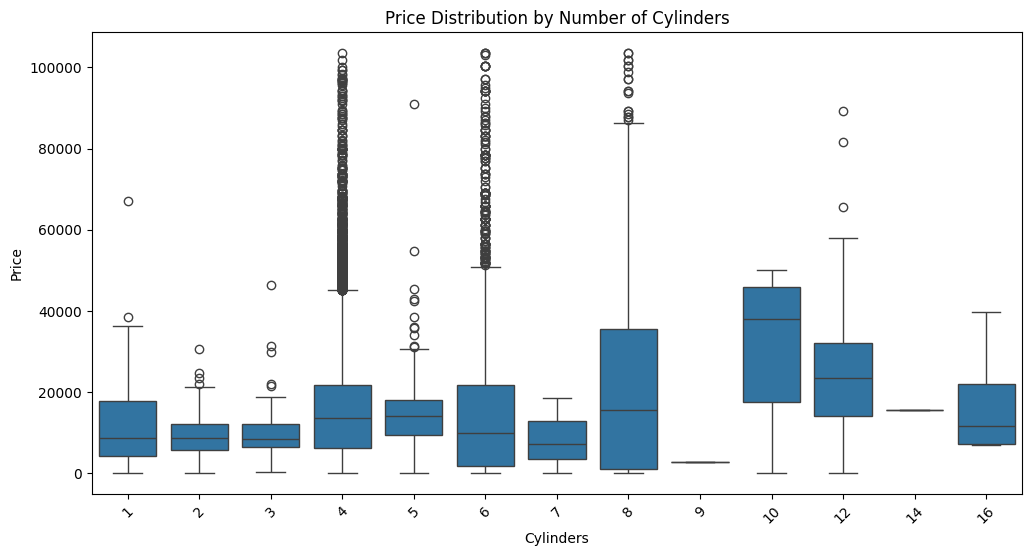

In [ ]:
# Kiểm tra Price của những xe có số Cylinders quá lẻ hoặc quá cao
plt.figure(figsize=(12,6))
sns.boxplot(data=df_model, x="Cylinders", y="Price")

plt.title("Price Distribution by Number of Cylinders")
plt.xticks(rotation=45)
plt.show()


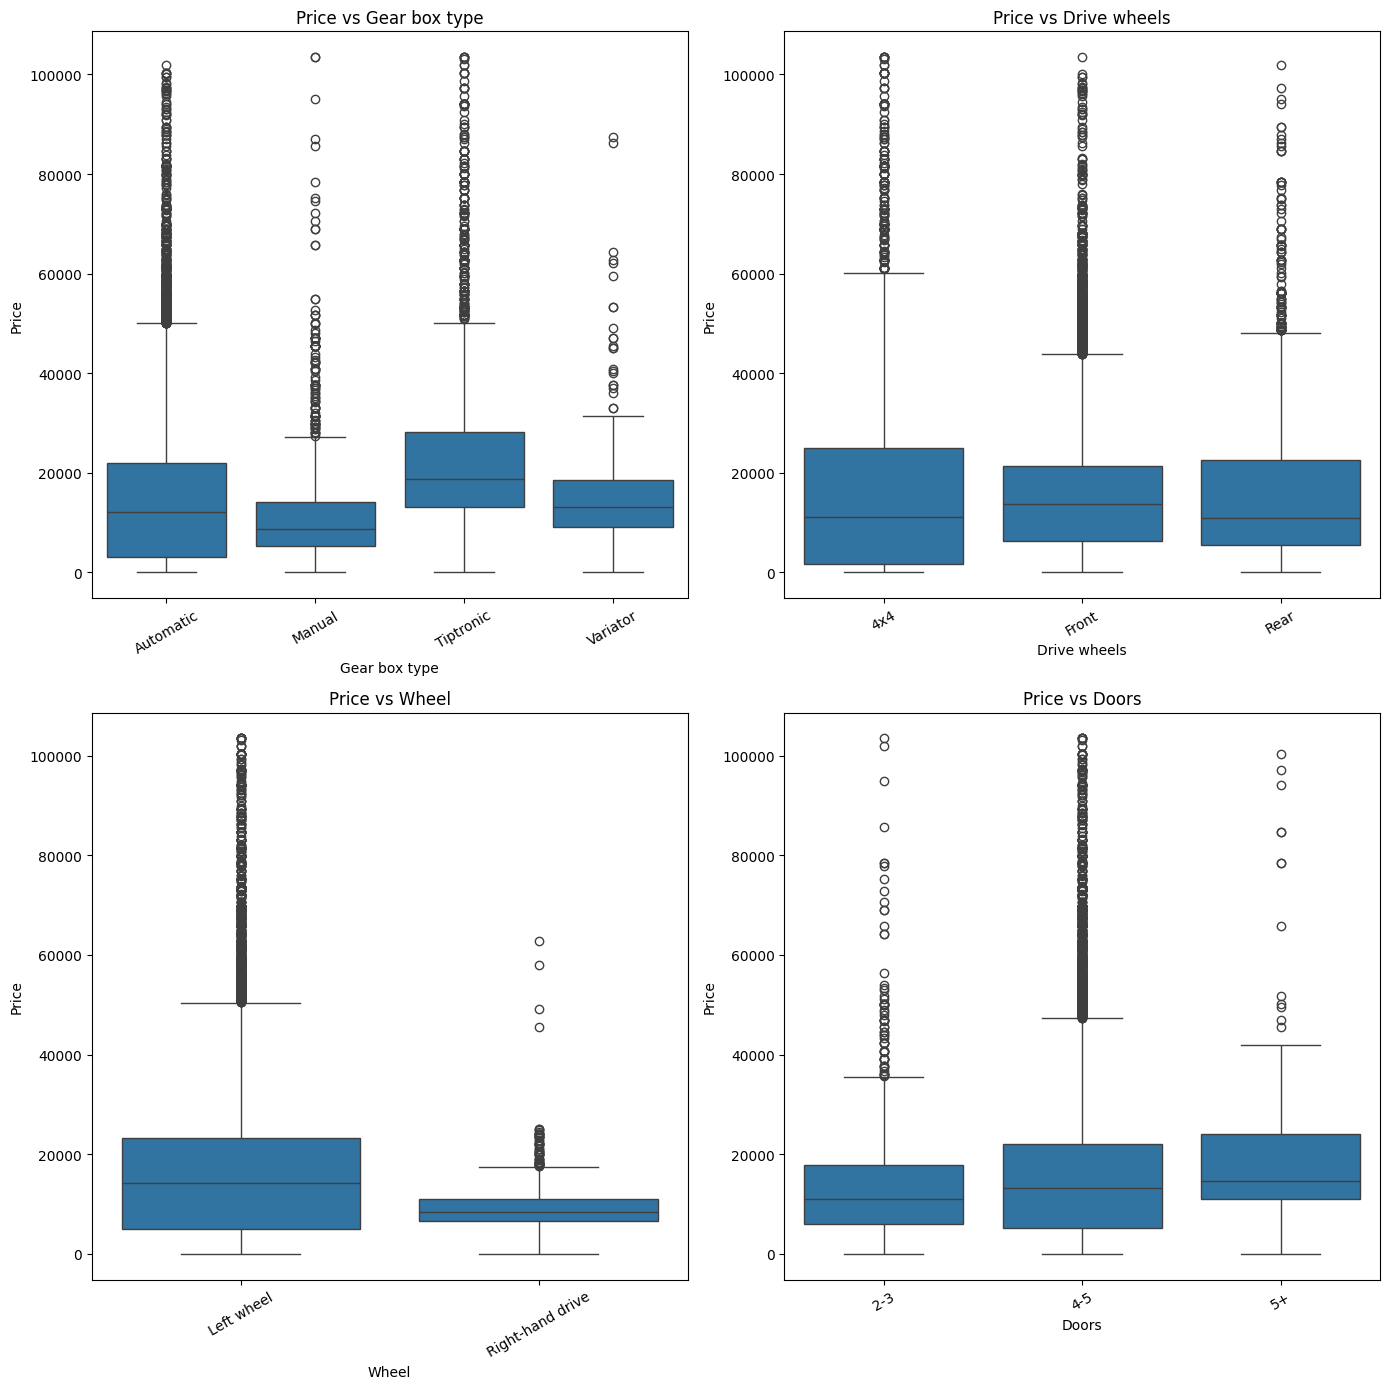

In [69]:
# Boxplot để kiểm tra mối quan hệ giữa Gear box type, Drive wheels, Wheel, Doors với Price

cat_features = ["Gear box type", "Drive wheels", "Wheel", "Doors"]

plt.figure(figsize=(14, 14))

for i, col in enumerate(cat_features):
    plt.subplot(2, 2, i + 1)

    sns.boxplot(
        data=df_model,
        x=col,
        y="Price"
    )

    plt.title(f"Price vs {col}")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

**Insight:**
- Nhiễu cực đoan: Các biến số như Cylinders, Gear box, hay Drive wheels không chỉ đơn thuần là kỹ thuật, mà là chỉ dấu của phân khúc. Những xe có 8 xi-lanh hoặc dẫn động 4x4, Tiptronic thường nằm ở "đuôi dài" của phân phối (giá cực cao).
- Đa số dữ liệu tập trung ở nhóm "phổ thông" (4 xi lanh, Automatic, Front-wheel), trong khi những "điểm dữ liệu ngoại lai" (outliers) có giá trị cực cao là nhân tố gây nhiễu lớn nhất cho mô hình hồi quy truyền thống nếu không được xử lý riêng biệt.

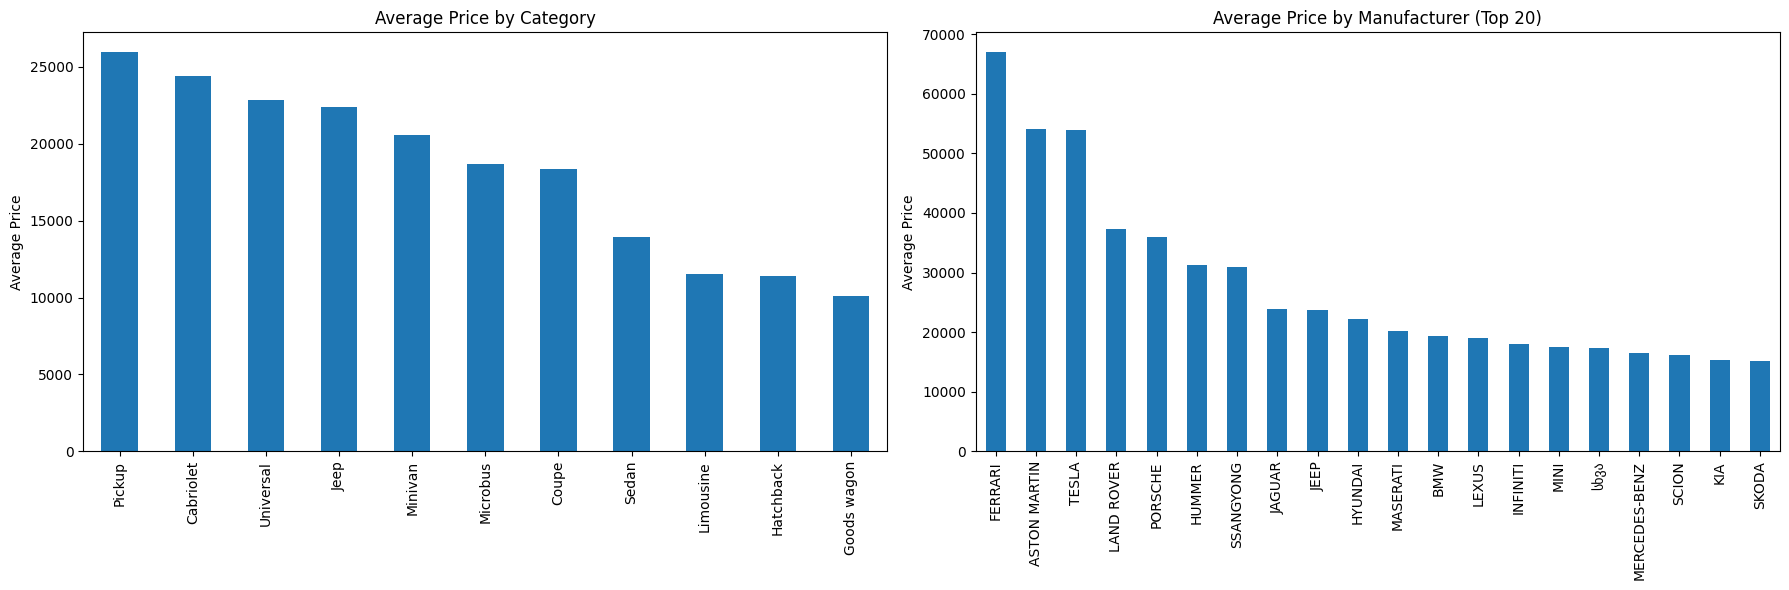

In [70]:
# Nhóm các xe theo category/ manufacturer và tính giá trung bình của mỗi nhóm
plots = {
    "Average Price by Category": df_model.groupby("Category")["Price"].mean().sort_values(ascending=False),
    "Average Price by Manufacturer (Top 20)": df_model.groupby("Manufacturer")["Price"].mean().sort_values(ascending=False).head(20)
}

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()

for i, (title, data) in enumerate(plots.items()):

    data.plot(
        kind='bar',
        ax=axes[i]
    )

    axes[i].set_title(title)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Average Price")

plt.tight_layout()
plt.show()

**Insight:**
- Nghịch lý giữa "Độ phổ biến" và "Giá trị": 
    - Loại xe: Sedan là loại xe phổ biến nhất với số lượng áp đảo, nhưng lại nằm ở nửa dưới về giá trung bình. Ngược lại, Pickup có số lượng rất thấp nhưng lại là loại xe có giá trung bình cao nhất. Như vậy, thị trường tập trung vào các mẫu xe Sedan cho nhu cầu đại chúng, trong khi các dòng xe như Pickup thuộc phân khúc đặc thù, giá trị cao và ít cạnh tranh về số lượng hơn.
    - Nhà sản xuất: Hyundai và Toyota dẫn đầu về tần suất xuất hiện trên thị trường, nhưng không lọt vào top 3 nhà sản xuất có giá trung bình cao nhất. Chiến lược kinh doanh của các hãng dẫn đầu thị trường là tối đa hóa doanh số thông qua các sản phẩm phổ thông, thay vì tập trung vào xe sang (như Ferrari, Aston Martin hay Tesla).
- Sự phân hóa thị trường của các dòng xe "ngách"
    - Dòng Jeep có sự cân bằng thú vị: nó nằm trong top 4 về giá trung bình và cũng nằm trong top 4 về tần suất xuất hiện (phổ biến) trong các loại xe. Jeep là một trường hợp đặc biệt—dù là dòng xe chuyên dụng nhưng lại đạt được mức độ phổ biến cao, cho thấy nhu cầu lớn và khả năng duy trì giá trị thương hiệu tốt của dòng xe này.
    - Tiềm năng của nhóm xe phổ thông: Nhóm các nhà sản xuất như Mercedes-Benz, Ford, Chevrolet có lượng xe lưu thông lớn đồng thời vẫn giữ được mức giá trung bình ổn định. Đây là nhóm các nhà sản xuất đạt được sự cân bằng giữa thị phần và biên lợi nhuận.

## **3.3. Binary Features**

In [72]:
# Lọc ra các Binary features (boolean)
binary_data=df_model.select_dtypes(include= 'bool')
binary_features=binary_data.columns.tolist()

print(f'There are {len(binary_features)} binary features:', '\n')
print(binary_features)

There are 3 binary features: 

['Leather interior', 'Turbo', 'Levy missing']


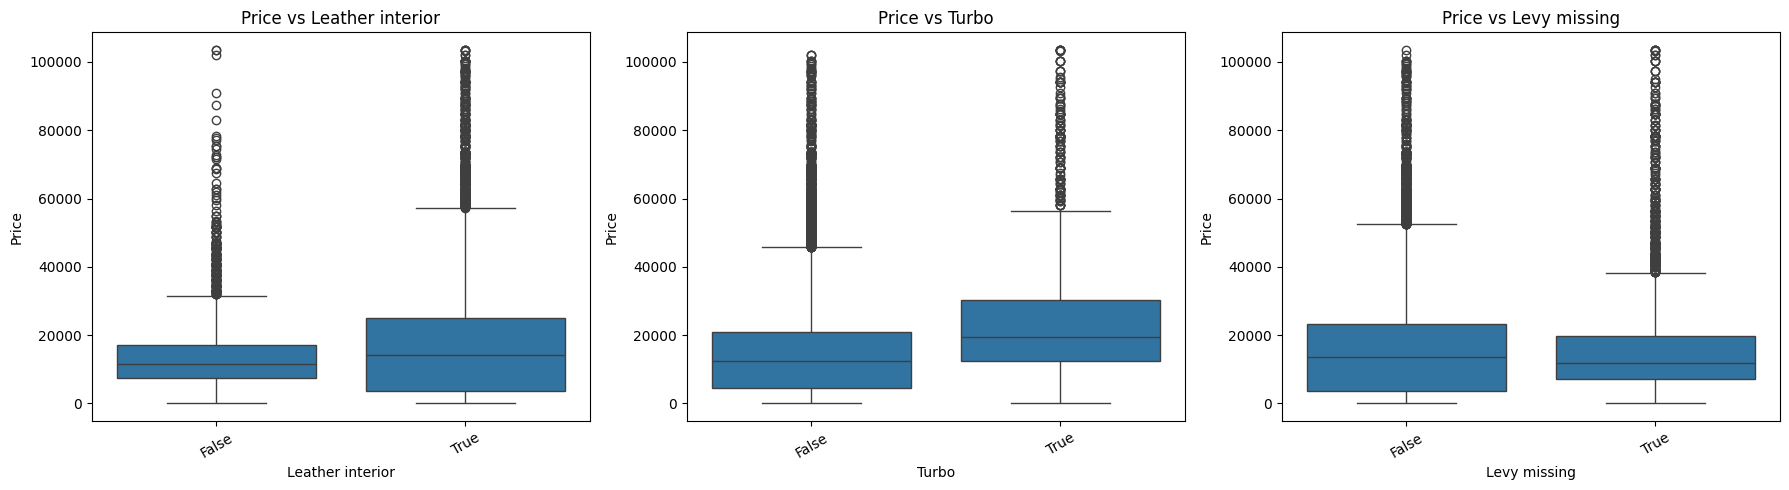

In [74]:
# Kiểm tra mối quan hệ giữa các biến Binary với Price bằng boxplot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

for i, col in enumerate(binary_features):

    sns.boxplot(
        data=df_model,
        x=col,
        y="Price",
        ax=axes[i]
    )

    axes[i].set_title(f"Price vs {col}")
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Insight:**
- Các xe có Leather interior (True) và Turbo (True) đều có mức giá trung vị và phân phối giá cao hơn hẳn so với xe không có các đặc tính này. Đây là đặc trưng mạnh giúp phân loại giá.
- Ở biểu đồ Levy missing, những xe có dữ liệu bị thiếu (True) có giá thấp hơn so với những xe có đầy đủ dữ liệu (False). Điều này cho thấy việc "mất dữ liệu" không phải là ngẫu nhiên, mà nó mang thông tin (có thể xe cũ, xe giá trị thấp nên không có thông tin thuế phí).
- Outliers: Cả 3 biểu đồ đều cho thấy rất nhiều điểm nằm ngoài râu hộp (outliers) ở phía trên (>60,000). Đây là các xe siêu sang hoặc xe đặc biệt, làm nhiễu mô hình dự báo giá phổ thông.

## **3.4. Check imbalance**

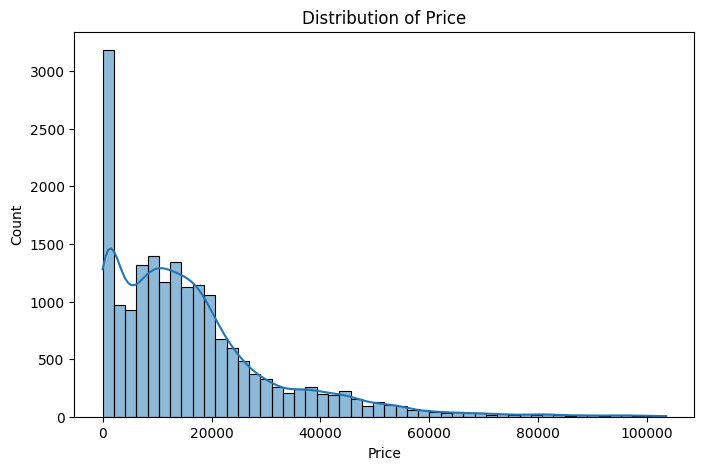

In [ ]:
# Check Imbalance in data

plt.figure(figsize=(8,5))
sns.histplot(df_model["Price"], bins=50, kde=True)

plt.title("Distribution of Price")
plt.show()

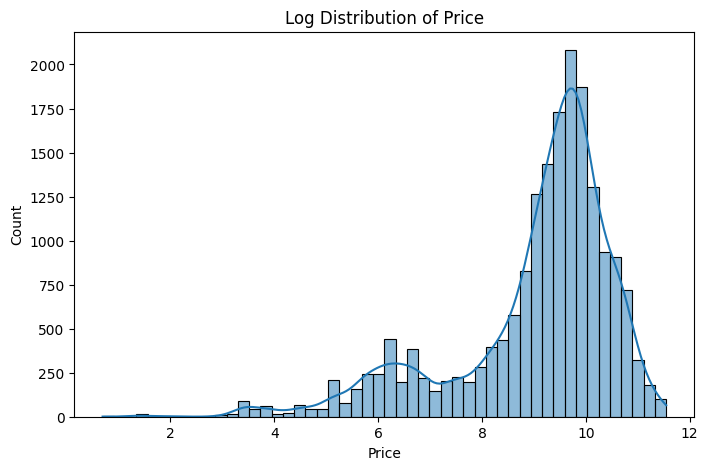

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(np.log1p(df_model["Price"]), bins=50, kde=True)

plt.title("Log Distribution of Price")
plt.show()

**Insight:**
- Về phân phối: Dữ liệu gốc bị lệch phải cực đoan do quá nhiều xe giá rẻ áp đảo. Việc áp dụng log-transform là bước "sống còn" để đưa dữ liệu về dạng gần chuẩn, giúp mô hình bớt bị nhiễu bởi các xe siêu sang và nhận diện rõ hơn các phân khúc giá.
- Về chiến lược: Biểu đồ sau log lộ rõ cấu trúc đa đỉnh (multimodal), chứng tỏ thị trường phân tách thành các nhóm xe rõ rệt thay vì một dải liên tục, nên dùng mô hình dựa trên cây để mô hình tự học các "ngưỡng giá" phân tầng này thay vì cố gắng tinh chỉnh thủ công các biến kỹ thuật.